Columns with NaNs: 34 out of 80


PoolQC          2909
MiscFeature     2814
Alley           2721
Fence           2348
MasVnrType      1766
FireplaceQu     1420
LotFrontage      486
GarageQual       159
GarageYrBlt      159
GarageCond       159
GarageFinish     159
GarageType       157
BsmtExposure      82
BsmtCond          82
BsmtQual          81
BsmtFinType2      80
BsmtFinType1      79
MasVnrArea        23
MSZoning           4
BsmtFullBath       2
dtype: int64


Top Numerical Correlations with SalePrice:


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

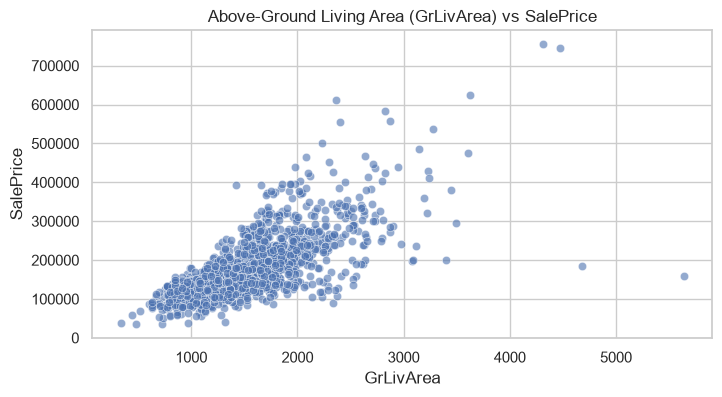

In [2]:
# 1. Check columns with missing values (combined train + test)
full_df = pd.concat([train.drop(columns=["SalePrice"]), test], ignore_index=True)
missing = full_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"Columns with NaNs: {len(missing)} out of {full_df.shape[1]}")
display(missing.head(20))

# 2. Top 10 numerical correlations with SalePrice + check GrLivArea (Living Area) for outliers
top_corr = train.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False).head(11)
print("\nTop Numerical Correlations with SalePrice:")
display(top_corr)

plt.figure(figsize=(8, 4))
sns.scatterplot(x=train["GrLivArea"], y=train["SalePrice"], alpha=0.6)
plt.title("Above-Ground Living Area (GrLivArea) vs SalePrice")
plt.show()

Train shape: (1460, 81) | Test shape: (1459, 80)
Raw SalePrice skewness: 1.883
Log1p SalePrice skewness: 0.121


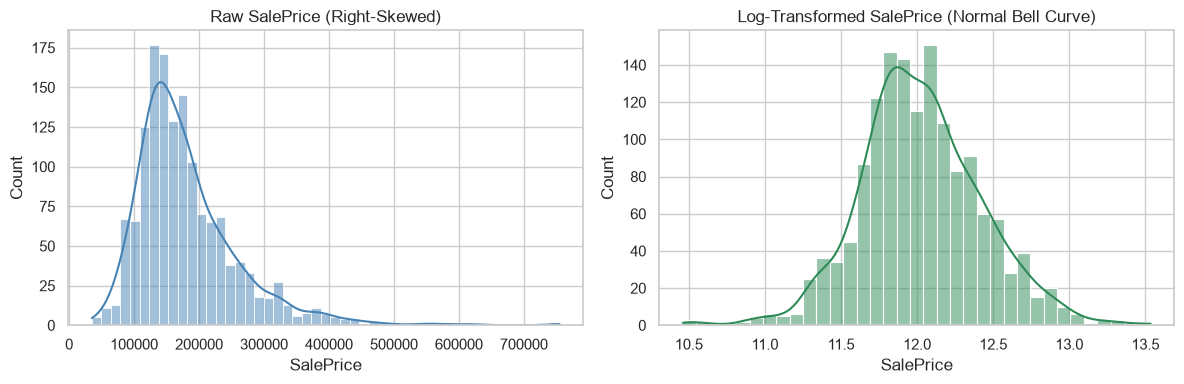

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print(f"Train shape: {train.shape} | Test shape: {test.shape}")
print(f"Raw SalePrice skewness: {train['SalePrice'].skew():.3f}")
print(f"Log1p SalePrice skewness: {np.log1p(train['SalePrice']).skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(train["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Raw SalePrice (Right-Skewed)")

sns.histplot(np.log1p(train["SalePrice"]), kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("Log-Transformed SalePrice (Normal Bell Curve)")

plt.tight_layout()
plt.show()

